In [1]:
%load_ext pyspecdata.ipy
import numpy as np
import scipy
from scipy.optimize import root_scalar

Here we take the aggregation number vs. $w_0$, and use
it to determine what w0 we want to get a
particular water loading.
There are many function definitions that
all come together at the end.

Start by defining a function to determine the
aggregation number using equation taken
from the RM 2H paper.
using a dictionary here is a bit
round-about, but it's because of how the
original code was written

In [2]:
params = {}
params['k'] = 0.174
params['zeroth'] = 15.1
params['first_b'] = 0.260
params['first_m'] = 7.15
params['second_l'] = 0.673
params['second_c'] = -37.1
def aggregation_number(params, w0):
    # exp(βn) = exp(βa) + exp(β(mx+b)) + exp(β(lx²+c))
    k = params['k']
    model = np.exp(k*params['zeroth'])
    model += np.exp(k*(params['first_m']*w0 + params['first_b']))
    model += np.exp(k*(params['second_l']*w0**2 + params['second_c']))
    model = np.log(model)/k
    # when infinite, assume the quadratic term dominates
    mask = ~np.isfinite(model)
    if np.isscalar(mask):
        if mask:
            model = params['second_l']*w0**2 + params['second_c']
            return w0*model
    elif any(mask):
        model[mask] = params['second_l']*w0[mask]**2 + params['second_c']
    return model

function to determine the weight of the water (in Da)
from the w0

In [3]:
def water_weight(w0):
    return 18*w0*aggregation_number(params,w0)

equations from Pal2011FluCorSpe for
determining the radius -- they define two
equations for two regimes

In [4]:
def smaller_radius(w):
    return 0.175*w+1.5
def larger_radius(w):
    delta = 1.5
    gamma = 0.043
    y = 20.4
    numerator = y*(1+2*gamma)
    radius = 3*delta*w/numerator*(
            1+numerator/3/w
            -numerator**2/9/w**2
            +5*numerator**3/81/w**3)
    return radius
@np.vectorize
def rm_radius(w):
    return smaller_radius(w) if w<20 else larger_radius(w)

These are the actual functions that you use
to get all the info about an RM, specified
either by $w_0$ or by weight

In [5]:
def rm_by_w0(thisw0):
    nbar = aggregation_number(params,thisw0)
    ww = water_weight(thisw0)/1e3
    nw = thisw0*nbar
    assert np.isclose(ww*1e3,18*nw), str(ww*1e3)+" doesn't match "+str(18*nw)
    print("at",thisw0,"\n",
          "number of aot is",nbar,"\n",
          "number of waters is",nw,"\n",
          "water weight is",ww,'kDa',"\n",
          "concentration needed for single loading",55.44/nw/1e-3,'mM',"\n",
          "diameter",2*rm_radius(thisw0),'nm',"\n",
          "diameter of water",2*rm_radius(thisw0)-3.0,'nm',"\n",
          )
def rm_by_weight(thisweight):
    result = root_scalar(
            lambda x: water_weight(x)-thisweight,
            x0=0,
            x1=thisweight/10)
    assert result.flag == 'converged'
    rounded = np.round(result.root*10)/10
    print("I find a weight of",thisweight,"at w0=",result.root,"\n",
            "confirming ", water_weight(result.root),"\n",
            "with rounding to",rounded,
            water_weight(
                rounded
                ))

In [6]:
rm_by_w0(3)

at 3 
 number of aot is 23.29117979004874 
 number of waters is 69.87353937014622 
 water weight is 1.2577237086626318 kDa 
 concentration needed for single loading 793.4334012524201 mM 
 diameter 4.05 nm 
 diameter of water 1.0499999999999998 nm 



In [7]:
rm_by_weight(10e3)

I find a weight of 10000.0 at w0= 8.796416294352039 
 confirming  10000.0 
 with rounding to 8.8 10008.132477260944


C:\Users\roman\AppData\Local\Temp\ipykernel_28840\585362542.py:12: RuntimeWarning: overflow encountered in exp
  model += np.exp(k*(params['first_m']*w0 + params['first_b']))
C:\Users\roman\AppData\Local\Temp\ipykernel_28840\585362542.py:13: RuntimeWarning: overflow encountered in exp
  model += np.exp(k*(params['second_l']*w0**2 + params['second_c']))


In [9]:
# Manuscript
# isooctane
# for w0=3
# Temperature 298.15 K (high)
# viscosity of isooctane at 298.15 K is 0.473 mPas 

eta = 0.473e-3
T = 298.15
hydrodynamic_radius = 4.05e-9/2
k= scipy.constants.k
tau= 4*pi*eta*hydrodynamic_radius**3/(3*k*T)
print('Tau is',tau/1e-9,'ns') 

Tau is 3.9967477241313953 ns


In [7]:
# isooctane
# for w0=3
# Temperature 323.16 K (high)
# viscosity of isooctane at 323.16 K is 0.365 mPas 

eta = 0.365e-3
T = 323.16
hydrodynamic_radius = 4.05e-9/2
k= scipy.constants.k
tau= 4*pi*eta*hydrodynamic_radius**3/(3*k*T)
print('Tau is',tau/1e-9,'ns') 

Tau is 2.8454808965722735 ns


In [25]:
# viscosity of isooctane at 273K is 0.65 mPas 
# for w0=3
eta = 0.65e-3
T = 273
hydrodynamic_radius = 4.05e-9/2
k= scipy.constants.k
tau= 4*pi*eta*hydrodynamic_radius**3/(3*k*T)
print('Tau is',tau/1e-9,'ns') 

Tau is 5.998340551443548 ns


In [8]:
# isooctane
# for w0=3
# Temperature 222.91 K (low)
# viscosity of isooctane at 222.91 K is 1.58 mPas 

eta = 1.58e-3
T = 222.91
hydrodynamic_radius = 4.05e-9/2
k= scipy.constants.k
tau= 4*pi*eta*hydrodynamic_radius**3/(3*k*T)

print('Tau is',tau/1e-9,'ns') 

Tau is 17.85697721025499 ns


In [26]:
SDE={}
SDE={'222.91':17.85697721025499, '273': 5.998340551443548, '323.16': 2.8454808965722735}

In [18]:
correlation_time_w3= {'263.808': 9.330471302845549e-09,
 '273.734': 5.414009444829644e-09,
 '283.23': 3.398810261093862e-09,
 '293.474': 2.2594769822819207e-09,
 '303.954': 1.518580757533853e-09,
 '313.666': 1.1168824469550482e-09,
 '323.482': 8.161958524190833e-10,
 '332.456': 6.136021633099168e-10}

In [19]:
correlation_time_w20 = {'263.666': 8.79480268958051e-09,
 '272.834': 4.201626401666716e-09,
 '282.939': 2.7966301436965588e-09,
 '292.621': 1.9548905289470708e-09,
 '302.773': 1.396117566724349e-09,
 '312.693': 9.746560319343618e-10,
 '322.676': 6.894436766138913e-10,
 '333.008': 5.037363223171206e-10}

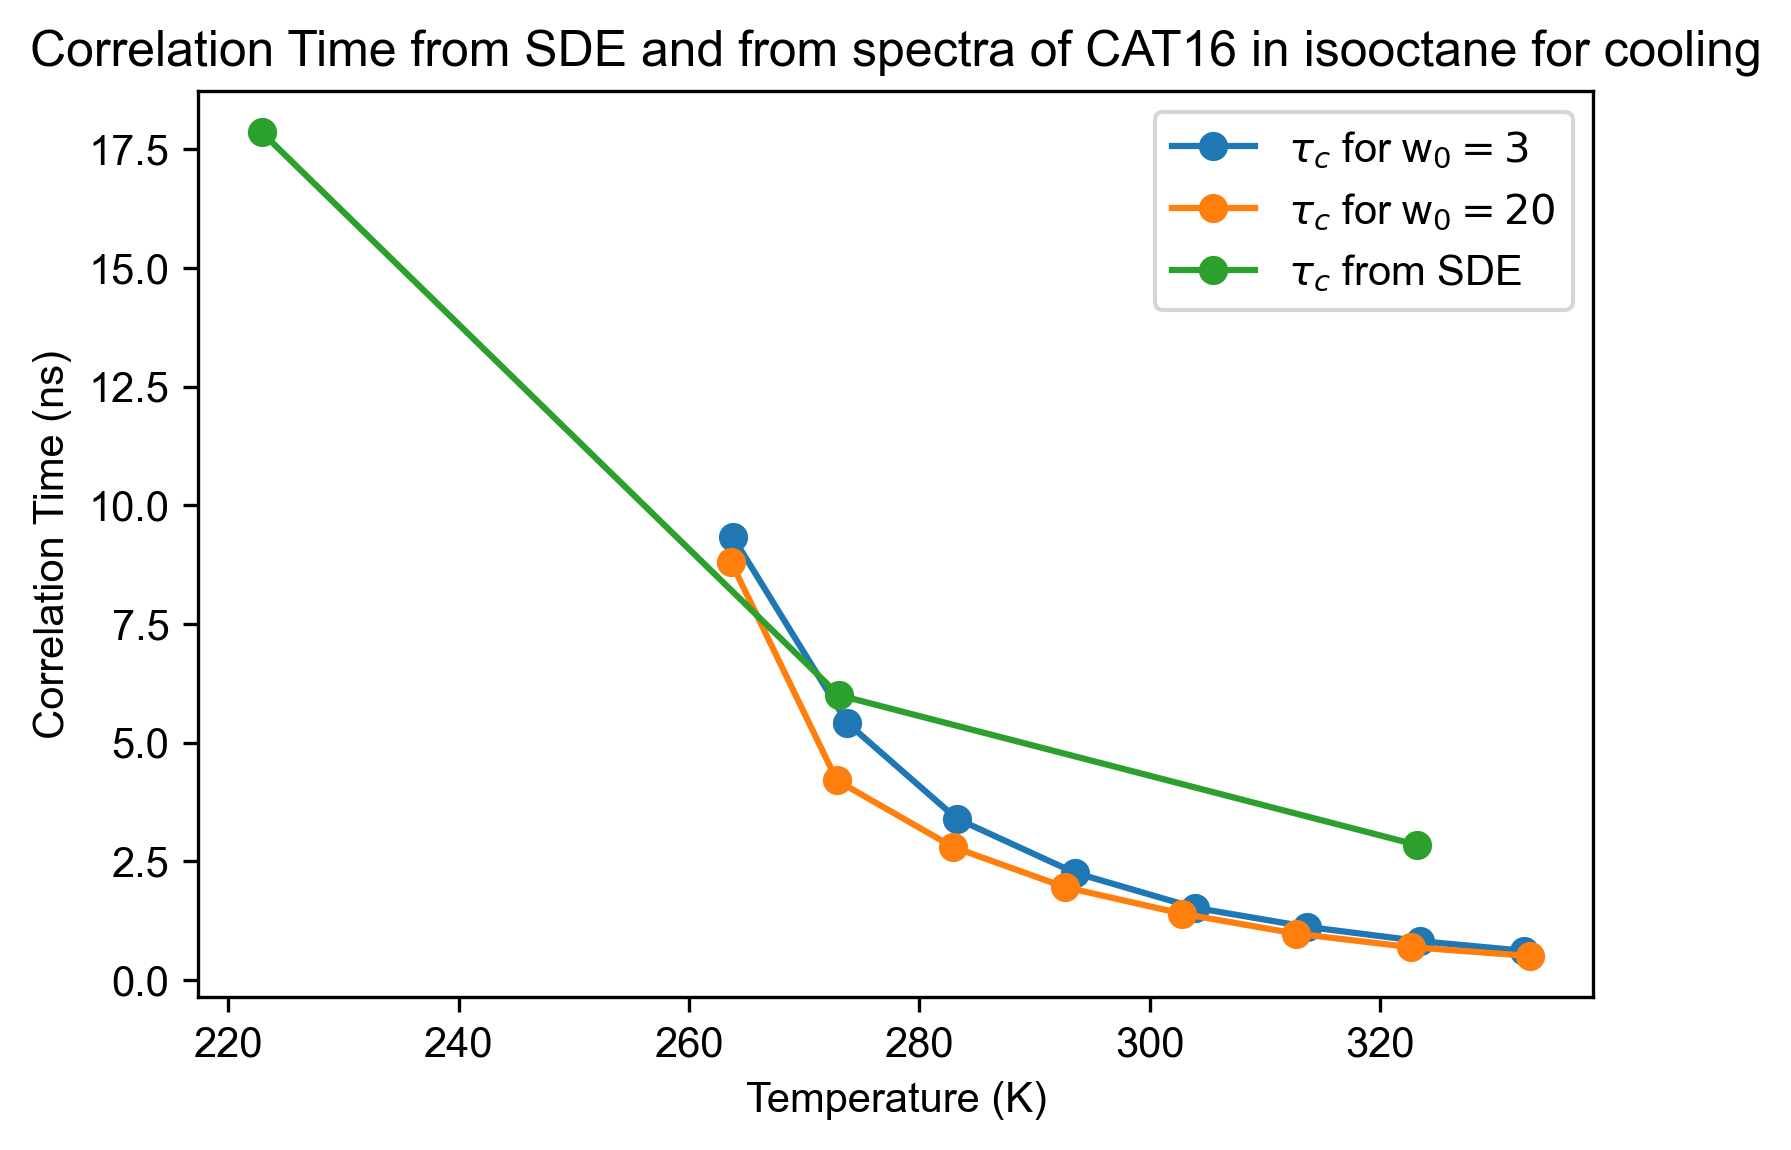

In [36]:
# W3
temp_w3= [float(temp_w3) for temp_w3 in correlation_time_w3.keys()]
tau_w3= list(correlation_time_w3.values())
figure(dpi=300, figsize=(6,4))
tau_ns_w3 = [t / 1e-9 for t in tau_w3]
plot(temp_w3, tau_ns_w3, linestyle='-',  marker='o', label=r"$\tau_c$ for w$_0=3$")

# w20
temp_w20= [float(temp_w20) for temp_w20 in correlation_time_w20.keys()]
tau_w20= list(correlation_time_w20.values())
tau_ns_w20 = [t20 / 1e-9 for t20 in tau_w20]
plot(temp_w20, tau_ns_w20, linestyle='-',  marker='o', label=r"$\tau_c$ for w$_0=20$")

# SDE
temp_SDE= [float(temp_SDE) for temp_SDE in SDE.keys()]
tau_SDE= list(SDE.values())
plot(temp_SDE, tau_SDE, linestyle='-',  marker='o', label=r"$\tau_c$ from SDE")

legend()
xlabel('Temperature (K)')
ylabel('Correlation Time (ns)')
title('Correlation Time from SDE and from spectra of CAT16 in isooctane for cooling')
show()

[3.7906356137797186, 3.6531815558169614, 3.5306994315573914, 3.407456878633201, 3.289971508846733, 3.1881045443242173, 3.091362115975541, 3.007916837115287]
[3.7926770990571406, 3.665232339077974, 3.53433072146293, 3.4173897293769078, 3.3028044112255714, 3.19802489982187, 3.0990839107959687, 3.0029308605198675]
[4.486115472612265, 3.663003663003663, 3.0944423814828563]


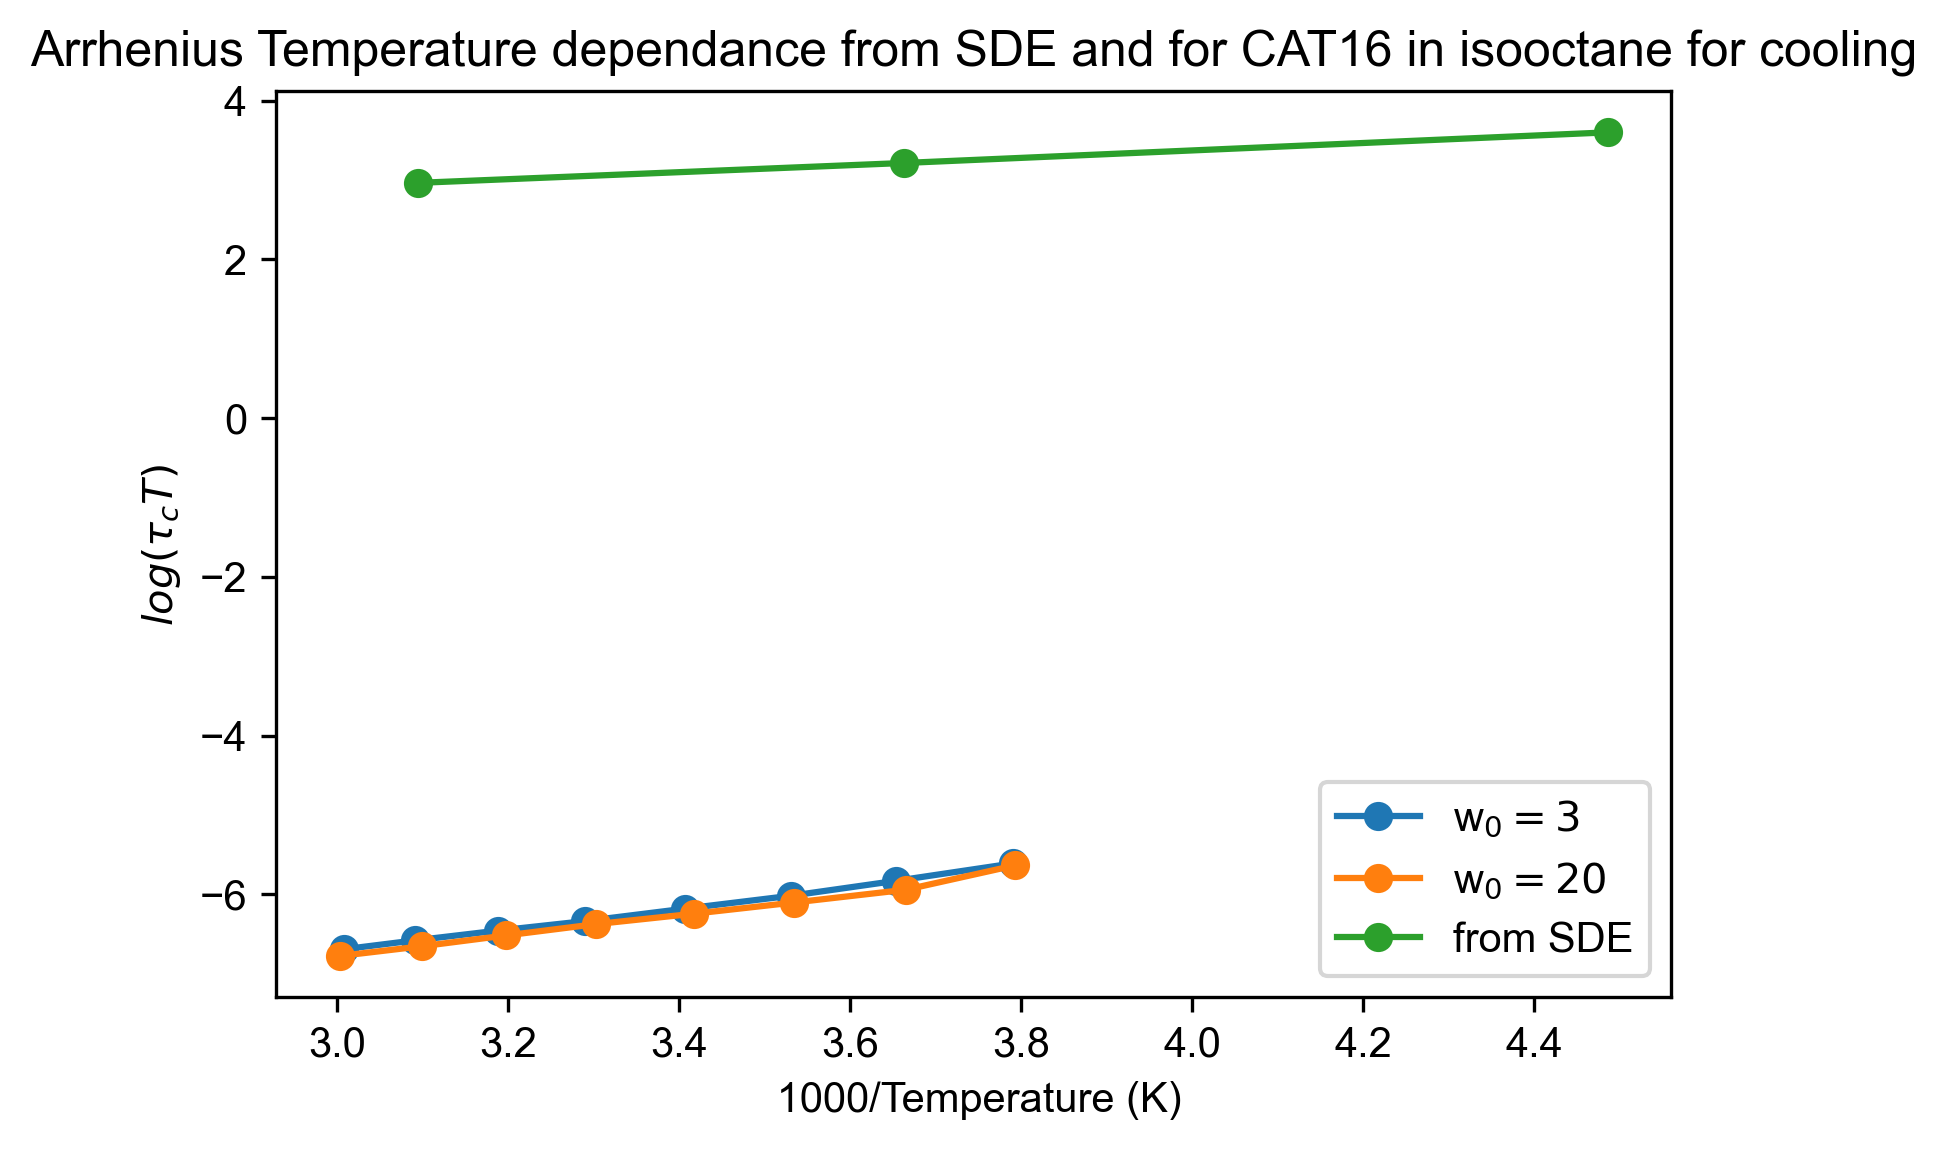

In [34]:
# Arrhenius
figure(dpi=300, figsize=(6,4))
T_w3= [1000/temp_w3 for temp_w3 in temp_w3]
T_w20= [1000/temp_w20 for temp_w20 in temp_w20]
T_SDE= [1000/temp_SDE for temp_SDE in temp_SDE]
print(T_w3)
print(T_w20)
print(T_SDE)

log_tauT_w3 = [log10(tau_w3*temp_w3) for tau_w3, temp_w3 in zip(tau_w3, temp_w3)]
log_tauT_w20 = [log10(tau_w20*temp_w20) for tau_w20, temp_w20 in zip(tau_w20, temp_w20)]
log_tauT_SDE = [log10(tau_SDE*temp_SDE) for tau_SDE, temp_SDE in zip(tau_SDE, temp_SDE)]

plot(T_w3, log_tauT_w3, linestyle='-',  marker='o', label=r"w$_0=3$")
plot(T_w20, log_tauT_w20, linestyle='-',  marker='o', label=r"w$_0=20$")
plot(T_SDE, log_tauT_SDE, linestyle='-',  marker='o', label=r"from SDE")

legend()
xlabel(' 1000/Temperature (K)')
ylabel(r"$log(\tau_cT)$")
title('Arrhenius Temperature dependance from SDE and for CAT16 in isooctane for cooling')
show()

In [10]:
# # viscosity of isooctane at 273K is 0.65 mPas 
# # for w0=20
# eta = 0.65e-3
# T = 273
# hydrodynamic_radius = 10.698767768078e-9/2
# k= scipy.constants.k
# tau= 4*pi*eta*hydrodynamic_radius**3/(3*k*T)
# print('Tau is',tau/1e-9,'ns') 

In [11]:
# # viscosity of isooctane at 323.16 K is 0.365 mPas 
# # for w0=20
# eta = 0.365e-3
# T = 323.16
# hydrodynamic_radius = 10.698767768078e-9/2
# k= scipy.constants.k
# tau= 4*pi*eta*hydrodynamic_radius**3/(3*k*T)
# print('Tau is',tau/1e-9,'ns') 

RS: For Dodecane

In [12]:
# # viscosity of Dodecane at 293K is 0.01049 kg/ms   
# # for w0=20
# eta = 0.01049
# T = 293
# hydrodynamic_radius = 10.698767768078e-9/2
# k= scipy.constants.k
# tau= 4*pi*eta*hydrodynamic_radius**3/(3*k*T)
# print('Tau is',tau/1e-9,'ns') 

In [13]:
# viscosity of Dodecane at 293K is 0.01049 kg/ms   
# for w0=3
eta = 0.001049
T = 293
hydrodynamic_radius = 4.05e-9/2
k= scipy.constants.k
tau= 4*pi*eta*hydrodynamic_radius**3/(3*k*T)
print('Tau is',tau/1e-9,'ns') 

Tau is 9.019620751382249 ns


In [14]:
# # viscosity of Dodecane at 283K is 0.00181 kg/ms   
# # for w0=3
# eta = 0.00181
# T = 283
# hydrodynamic_radius = 4.05e-9/2
# k= scipy.constants.k
# tau= 4*pi*eta*hydrodynamic_radius**3/(3*k*T)
# print('Tau is',tau/1e-9,'ns') 

In [15]:
# # viscosity of Dodecane at 273K is 0.00226 kg/ms   
# # for w0=3
# eta = 0.00226
# T = 273
# hydrodynamic_radius = 4.05e-9/2
# k= scipy.constants.k
# tau= 4*pi*eta*hydrodynamic_radius**3/(3*k*T)
# print('Tau is',tau/1e-9,'ns') 

In [16]:
# viscosity of Dodecane at 263K is 0.00290 kg/ms   
# for w0=3
eta = 0.00290
T = 263
hydrodynamic_radius = 4.05e-9/2
k= scipy.constants.k
tau= 4*pi*eta*hydrodynamic_radius**3/(3*k*T)
print('Tau is',tau/1e-9,'ns') 

Tau is 27.77938704052563 ns
